In [1]:
import numpy as np
X=np.array([1,2,3,4,5],dtype=float)
y=np.array([2,4,6,8,10],dtype=float)
print(X)
print(y)

[1. 2. 3. 4. 5.]
[ 2.  4.  6.  8. 10.]


In [2]:
w=0.0
b=0.0
y_pred0=w*X[0]+b
print(y_pred0)

0.0


In [3]:
y_pred=w*X+b
y_pred
mse=np.mean((y_pred-y)**2)
print(mse)

44.0


In [4]:
dw=((2/len(X))*np.sum(X*(y_pred-y)))
db=((2/len(X))*np.sum(y_pred-y))
print(dw)
print(db)

-44.0
-12.0


In [5]:
learning_rate=[0.001,0.01,0.5]


In [8]:
loss_history = []  # Outer list

for j in range(0, 3):
    w = 0.0  
    b = 0.0
    # Append an empty list that will hold the 100 iterations for this specific LR
    loss_history.append([]) 
    
    for i in range(0, 100):
        y_pred = w * X + b
        dw = (2 / len(X)) * np.sum(X * (y_pred - y))
        db = (2 / len(X)) * np.sum(y_pred - y)
        w = w - learning_rate[j] * dw
        b = b - learning_rate[j] * db
        loss = np.mean((y_pred - y) ** 2)
        
        # Append to the sublist at index j
        loss_history[j].append(loss)
    
    final_pred = w * X + b
    final_mse = np.mean((final_pred - y) ** 2)
    
    print(f"\n--- Results for Learning Rate: {learning_rate[j]} ---")
    print("Final weight:", w)
    print("Final bias:", b)
    print("Final MSE:", final_mse)
    


--- Results for Learning Rate: 0.001 ---
Final weight: 1.6928167263549765
Final bias: 0.4504636608703611
Final MSE: 0.4106452974190605

--- Results for Learning Rate: 0.01 ---
Final weight: 1.8984326022295357
Final bias: 0.36669053309859806
Final MSE: 0.02447442684930146

--- Results for Learning Rate: 0.5 ---
Final weight: -5.439886800102989e+103
Final bias: -1.5067614147631723e+103
Final MSE: 3.7696605152474935e+208


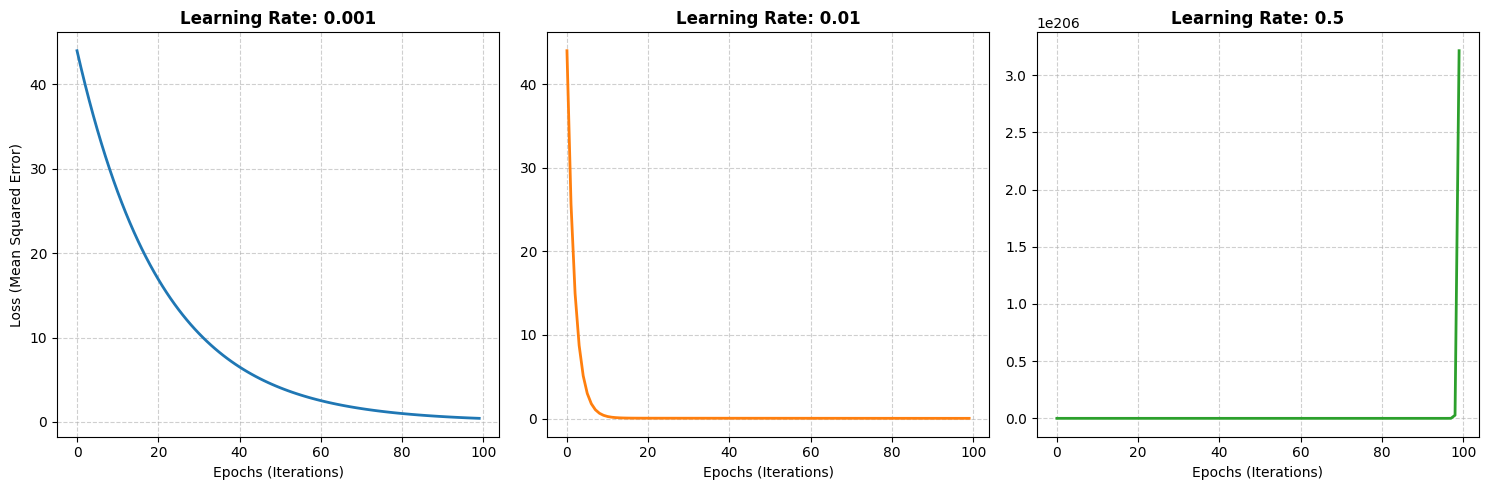

In [9]:
import matplotlib.pyplot as plt 
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for j, losses in enumerate(loss_history):
    ax = axes[j]
    ax.plot(losses, color=f'C{j}', linewidth=2)
 
    ax.set_title(f'Learning Rate: {learning_rate[j]}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Epochs (Iterations)', fontsize=10)
    
    # Add a Y-axis label only to the first plot to avoid clutter
    if j == 0:
        ax.set_ylabel('Loss (Mean Squared Error)', fontsize=10)
        
    ax.grid(True, linestyle='--', alpha=0.6)

# Automatically adjust spacing so text doesn't overlap
plt.tight_layout()

# Render the subplots
plt.show()
